# 📘 Notebook 03: House Prices, What Makes a House Expensive?

### Course: *From Questions to Answers: Classic Datasets, Fully Explored*
**Instructor:** Ioannis Tsioulis

*Dataset 3 · Ames, Iowa house sales 2006 to 2010 (2,930 houses, 82 columns)*

---

> 💡 **This notebook is already run.** Every table and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything. To experiment, choose **Runtime → Run all** in Colab; the whole notebook runs in about a minute. If you rerun it, numbers from the models may differ slightly in the last digits, because Colab may have newer library versions.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Find your way in a dataset with **many columns** without looking at all of them
- Tell a **missing value** from a value that means **"none"**
- Recognise a **skewed target** and use a **log transform** for it
- Find **outliers** and decide, with a reason, whether to keep them
- Spot **redundant columns** that measure the same thing
- Build **regression** baselines and measure them in **euros of error**, not in abstract scores

> **Prerequisites:** [Notebook 01: Titanic](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-questions-to-answers/01_titanic.ipynb).
>
> 🔭 **Why this notebook matters:** the Titanic and the penguins had a handful of columns; real business data often has dozens or hundreds. The question changes from *"what does each column say?"* to *"which few columns matter, and how do I find them fast?"*. And the answer is now a **number**, a price, so we must think about how wrong a prediction is allowed to be. This dataset was put together by Professor Dean De Cock as a modern replacement for the old Boston housing data, and it is the source of the famous Kaggle competition "House Prices".

## 0. The question

The city assessor of Ames, Iowa recorded every house sold between 2006 and 2010, with 80 descriptions of each house: size, quality, age, neighbourhood, garage, basement, pool, and many more.

**Our question:** *What makes a house expensive?* More precisely:

1. Which **few** of the 80 descriptions matter most?
2. Are there houses that do **not follow** the general pattern, and why?
3. How close can a model get to the real price, measured in dollars?

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80

## 1. Loading the data from a URL

The file is the original dataset published by De Cock in the *Journal of Statistics Education*. It is separated by tabs, not commas, so we tell `read_csv` with `sep="\t"`. (The Kaggle competition uses the same houses with slightly different column names, for example `GrLivArea` instead of `Gr Liv Area`.)

In [2]:
URL = "https://jse.amstat.org/v19n3/decock/AmesHousing.txt"
df = pd.read_csv(URL, sep="\t")
print(df.shape)
df.iloc[:5, :12]

(2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside


**What we see.** 2,930 houses and 82 columns: an order number, a parcel identifier (`PID`), 79 descriptions and the `SalePrice`. We show only the first 12 columns; printing all 82 would show nothing useful. With this many columns, the first step is not to read them, but to **summarise** them.

In [3]:
types = df.dtypes.value_counts()
print(types)
print()
print("Numeric columns:", df.select_dtypes("number").shape[1], " Text columns:", df.select_dtypes("object").shape[1])

object     43
int64      28
float64    11
dtype: int64

Numeric columns: 39  Text columns: 43


**What we see.** 39 columns are numbers (areas, years, counts, quality scores) and 43 are text categories (neighbourhood, roof type, heating). We will handle the two kinds differently: numbers through correlations and scatter plots, categories through group medians.

## 2. The target: sale price

count      2930.0
mean     180796.0
std       79887.0
min       12789.0
25%      129500.0
50%      160000.0
75%      213500.0
max      755000.0
Name: SalePrice, dtype: float64


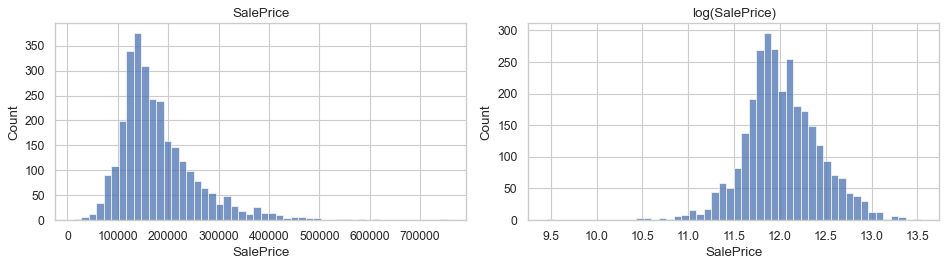

Skewness: price 1.74  log(price) -0.01


In [4]:
print(df["SalePrice"].describe().round(0))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(df["SalePrice"], bins=50, ax=axes[0]).set_title("SalePrice")
sns.histplot(np.log(df["SalePrice"]), bins=50, ax=axes[1]).set_title("log(SalePrice)")
plt.tight_layout()
plt.show()
print("Skewness: price", round(df["SalePrice"].skew(), 2), " log(price)", round(np.log(df["SalePrice"]).skew(), 2))

**What we see.** The median house sold for **160,000 dollars**, but prices run from **12,789** to **755,000**, and the mean (**180,796**) is pulled above the median by a long tail of expensive houses. The skewness is **1.74**. After taking the **logarithm**, the distribution becomes almost perfectly symmetric (skewness **-0.01**).

This matters for two reasons. Prices **grow by percentages**: a better kitchen adds about the same *percentage* to a cheap house and an expensive one, not the same amount of dollars, and the log turns percentages into additions. And many models, linear regression first of all, work best when errors are symmetric. We will test this claim in Section 7 rather than take it on trust.

## 3. Missing values: missing, or "none"?

In [5]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(len(missing), "columns have gaps")
missing.head(12)

27 columns have gaps


Pool QC          2917
Misc Feature     2824
Alley            2732
Fence            2358
Fireplace Qu     1422
Lot Frontage      490
Garage Cond       159
Garage Qual       159
Garage Finish     159
Garage Yr Blt     159
Garage Type       157
Bsmt Exposure      83
dtype: int64

**What we see.** 27 columns have gaps, and four of them are almost completely empty: `Pool QC` is missing for **2,917** of 2,930 houses, `Misc Feature` for 2,824, `Alley` for 2,732.

### Intuition first
Should we drop these columns, or fill them with something? First read what the gap **means**. The documentation of the dataset says that `Pool QC` (pool quality) is empty when the house **has no pool**. The value is not unknown: it is "none".

In [6]:
print(df["Pool QC"].value_counts(dropna=False))
print()
print("Houses with no garage quality AND zero garage cars:", ((df["Garage Qual"].isna()) & (df["Garage Cars"] == 0)).sum())

NaN    2917
Ex        4
Gd        4
TA        3
Fa        2
Name: Pool QC, dtype: int64

Houses with no garage quality AND zero garage cars: 157


**What we see.** Only 13 houses have a pool, so `Pool QC` is empty for the other 2,917. The garage columns tell the same story: the 157 houses with no garage type are the 157 houses with **zero** garage spaces. Here, `NaN` is a **coded answer**, and the correct "fill" is the word "None", or 0 for areas.

This is the opposite of the Titanic, where a missing age really was unknown. **Always read the documentation before filling a gap.** The only truly unknown column of any size is `Lot Frontage` (490 missing, the length of the street side of the plot), which a careful analyst would fill from similar houses in the same neighbourhood.

## 4. Which columns matter? Start with numbers

In [7]:
correlations = df.select_dtypes("number").corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)
correlations.head(10).to_frame("correlation with price")

,correlation with price
Overall Qual,0.799
Gr Liv Area,0.707
Garage Cars,0.648
Garage Area,0.640
Total Bsmt SF,0.632
1st Flr SF,0.622
Year Built,0.558
Full Bath,0.546
Year Remod/Add,0.533
Garage Yr Blt,0.527


**What we see.** With 40 numeric columns, a correlation ranking is a quick first filter. The top is very clear:
- `Overall Qual` (**0.80**), the assessor's rating of materials and finish from 1 to 10.
- `Gr Liv Area` (**0.71**), the living area above ground in square feet.
- Garage size (`Garage Cars` **0.65**, `Garage Area` **0.64**), basement area (**0.63**), year built (**0.56**).

A ranking is a starting point, not an answer. It cannot see curved relationships, and as the next sections show, it cannot see outliers or columns that duplicate each other.

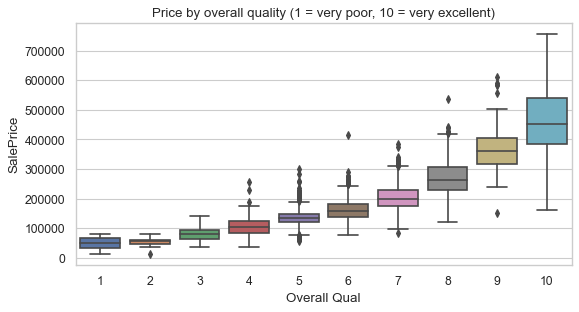

Overall Qual,1,2,3,4,5,6,7,8,9,10
median price,50150.0,57625.0,81200.0,105000.0,133000.0,159500.0,200000.0,264530.5,360000.0,451950.0


In [8]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="Overall Qual", y="SalePrice")
plt.title("Price by overall quality (1 = very poor, 10 = very excellent)")
plt.show()
df.groupby("Overall Qual")["SalePrice"].median().to_frame("median price").T

**What we see.** A staircase: every step up in quality raises the median price, from **50,150** at quality 1 to **451,950** at quality 10. Look at the **steps**: from 5 to 6 the median rises by 26,500, from 9 to 10 by about 92,000. The steps grow as the price grows, which is the percentage growth we saw in Section 2 again.

## 5. Outliers: houses that break the pattern

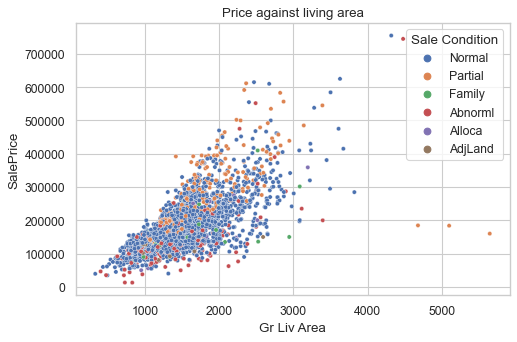

,Gr Liv Area,SalePrice,Sale Condition,Neighborhood
1498,5642,160000,Partial,Edwards
1760,4476,745000,Abnorml,NoRidge
1767,4316,755000,Normal,NoRidge
2180,5095,183850,Partial,Edwards
2181,4676,184750,Partial,Edwards


In [9]:
plt.figure(figsize=(7, 4.5))
sns.scatterplot(data=df, x="Gr Liv Area", y="SalePrice", hue="Sale Condition", s=15)
plt.title("Price against living area")
plt.show()
df.loc[df["Gr Liv Area"] > 4000, ["Gr Liv Area", "SalePrice", "Sale Condition", "Neighborhood"]]

**What we see.** Price rises with living area, as expected, but in the bottom right corner sit **three huge houses** (4,676 to 5,642 square feet) that sold for only **160,000 to 185,000 dollars**, about the price of a house a third of their size. All three are `Partial` sales: houses sold before they were finished. Two other very large houses sold for 745,000 and 755,000, in line with the trend.

**Decision.** De Cock himself recommends removing houses above 4,000 square feet before modelling, because they are unusual sales that would pull a model's line towards themselves. We remove all five and **say so**: our conclusions then apply to houses up to 4,000 square feet, which is 99.8% of the market. The key is that an outlier is removed for a **reason you can state**, never just because it is inconvenient.

In [10]:
df = df[df["Gr Liv Area"] <= 4000].reset_index(drop=True)
print(len(df), "houses kept")

2925 houses kept


## 6. Categories and redundant columns

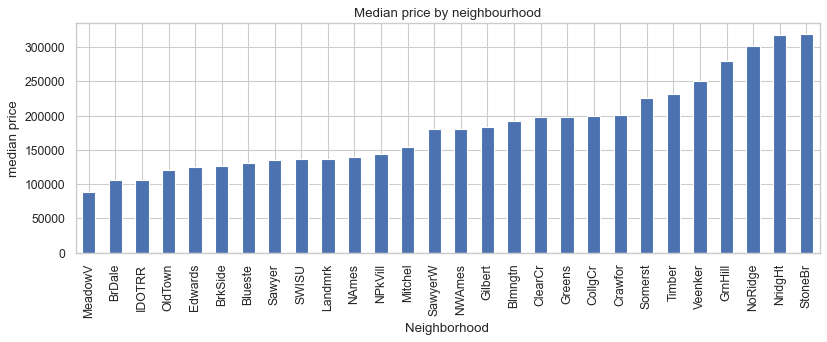

Cheapest: MeadowV 88250   Most expensive: StoneBr 319000


In [11]:
by_area = df.groupby("Neighborhood")["SalePrice"].median().sort_values()
plt.figure(figsize=(12, 3.8))
by_area.plot.bar()
plt.ylabel("median price")
plt.title("Median price by neighbourhood")
plt.show()
print("Cheapest:", by_area.index[0], int(by_area.iloc[0]), "  Most expensive:", by_area.index[-1], int(by_area.iloc[-1]))

**What we see.** Location matters a lot: the median house in **MeadowV** sold for **88,250**, and in **StoneBr** for **319,000**, more than three and a half times as much. Neighbourhood is a text column, so it never appeared in the correlation ranking of Section 4. **A correlation table only sees numbers**; categories need their own look.

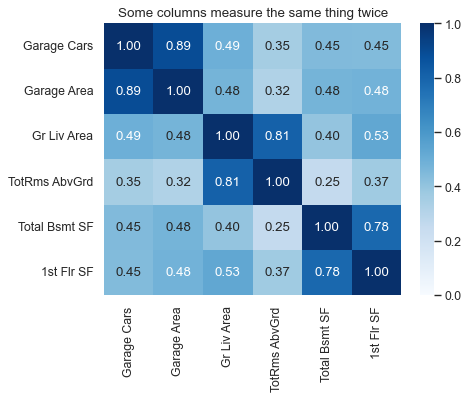

In [12]:
pair = ["Garage Cars", "Garage Area", "Gr Liv Area", "TotRms AbvGrd", "Total Bsmt SF", "1st Flr SF"]
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[pair].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Some columns measure the same thing twice")
plt.show()

**What we see.** Several pairs are near copies: garage **cars** and garage **area** (**0.89**), living area and number of **rooms** above ground, basement area and **first floor** area (the first floor usually sits on the basement). This is **redundancy**, and in a linear model it causes **multicollinearity**: when two columns carry the same information, the model cannot decide how to split the credit between them, and their coefficients become unstable. We keep one of each pair: `Garage Cars`, `Gr Liv Area`, `Total Bsmt SF`.

## 7. How close can we get? Regression baselines

### Intuition first
For a number, "accuracy" makes no sense. We measure the **mean absolute error (MAE)**: on average, how many dollars is the prediction away from the real price? A real estate agent understands "within 17,000 dollars"; nobody understands "R² of 0.91".

The simplest baseline: predict the **median price** for every house.

In [13]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

y = df["SalePrice"]
cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}
results["median for every house"] = mean_absolute_error(y, np.full(len(y), y.median()))

area = cross_val_predict(LinearRegression(), df[["Gr Liv Area"]], y, cv=cv)
results["living area only (linear)"] = mean_absolute_error(y, area)

features = ["Overall Qual", "Gr Liv Area", "Garage Cars", "Total Bsmt SF", "Year Built",
            "Full Bath", "Year Remod/Add", "Fireplaces", "Lot Area"]
X = df[features].fillna(0)
results["9 features (linear)"] = mean_absolute_error(y, cross_val_predict(LinearRegression(), X, y, cv=cv))
results["9 features, log price (linear)"] = mean_absolute_error(y, np.exp(cross_val_predict(LinearRegression(), X, np.log(y), cv=cv)))

Xn = pd.get_dummies(X.assign(Neighborhood=df["Neighborhood"]), drop_first=True)
results["+ neighbourhood, log price (linear)"] = mean_absolute_error(y, np.exp(cross_val_predict(LinearRegression(), Xn, np.log(y), cv=cv)))
results["+ neighbourhood (random forest)"] = mean_absolute_error(y, cross_val_predict(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), Xn, y, cv=cv))

pd.Series(results, name="mean absolute error ($)").round(0).to_frame()

,mean absolute error ($)
median for every house,55730.0
living area only (linear),38275.0
9 features (linear),22655.0
"9 features, log price (linear)",18052.0
"+ neighbourhood, log price (linear)",16946.0
+ neighbourhood (random forest),17093.0


**What we see.** Each step of the exploration becomes a measurable gain:
- Predicting the median for every house misses by **55,730 dollars** on average.
- Living area alone brings this down to **38,275**.
- Nine features chosen from the exploration: **22,655**.
- The **same nine** features with the **log price**: **18,052**, a 20% improvement for one line of code. The skewness we found in Section 2 was real.
- Adding the **neighbourhood**: **16,946**, about 10% of the median price.
- A **random forest** on the same data: **17,093**, no better than the linear model.

That last line is worth remembering. A carefully explored dataset with a few good transformations made a simple linear model as good as a forest of 300 trees, and the linear model can be explained in one sentence per feature.

In [14]:
final = LinearRegression().fit(Xn, np.log(y))
effect = pd.Series(final.coef_, index=Xn.columns)[features]
(100 * (np.exp(effect) - 1)).round(2).to_frame("% change in price per unit")

,% change in price per unit
Overall Qual,9.13
Gr Liv Area,0.02
Garage Cars,5.22
Total Bsmt SF,0.01
Year Built,0.20
Full Bath,-2.64
Year Remod/Add,0.26
Fireplaces,4.64
Lot Area,0.00


**What we see.** Because the model predicts the **log** of the price, each coefficient converts to a **percentage**, **with everything else held fixed**:
- one point of overall quality: **+9.1%**;
- one more garage space: **+5.2%**; one more fireplace: **+4.6%**;
- 100 more square feet of living area: about **+2%** (0.02% per square foot).

One number looks wrong: an extra **full bathroom** comes out at **-2.6%**. It is not a mistake. "Everything else held fixed" includes the living area, so the model compares two houses of the **same size**, one of which has used some of that space for another bathroom instead of a room. A coefficient answers a "holding everything else fixed" question, which is not always the question we had in mind. Percentages per unit are the language an appraiser uses, and they are another reward for the log transform.

## 8. Answer to the question

*What makes a house expensive?*

1. **Quality and size first:** the assessor's overall quality score (correlation 0.80) and the living area (0.71), followed by garage, basement and age.
2. **Location:** the median price varies more than threefold between neighbourhoods, which a correlation table cannot even see.
3. **Prices grow in percentages:** on a log scale the price becomes symmetric, and a linear model improves its error by 20%.
4. **A few houses break the pattern:** very large unfinished houses sold cheaply. We removed the five houses over 4,000 square feet, as the dataset's author recommends, and said so.
5. A linear model with nine features, the neighbourhood and a log price misses by about **17,000 dollars** on average, as well as a random forest, and every one of its coefficients can be read as a percentage.

## 🚀 Going further (for experienced students)

### A. All 80 columns in one leak-free pipeline
Top Kaggle notebooks use **every** column: fill "none" categories with the word `None`, fill numbers with the median, one-hot encode the categories, and fit a **regularised** linear model (`Ridge`), which shrinks the coefficients so that hundreds of columns do not overfit. A `Pipeline` keeps every step inside cross-validation.

In [15]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import RidgeCV

all_cols = df.drop(columns=["Order", "PID", "SalePrice"])
num_cols = all_cols.select_dtypes("number").columns
cat_cols = all_cols.select_dtypes("object").columns
prepare = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"), OneHotEncoder(handle_unknown="ignore")), cat_cols),
])
ridge = Pipeline([("prepare", prepare), ("model", RidgeCV(alphas=np.logspace(-1, 3, 30)))])
ridge_pred = np.exp(cross_val_predict(ridge, all_cols, np.log(y), cv=cv))
print("Ridge on all columns, log price:", round(mean_absolute_error(y, ridge_pred)), "dollars")

Ridge on all columns, log price: 13066 dollars


**What we see.** Using **all** columns with regularisation brings the error down to **13,066 dollars**, against 16,946 for our nine hand-picked features plus neighbourhood, a 23% improvement. The exploration told us *which* columns matter and *how* to treat them (log price, "None" for absent features, outliers removed); the pipeline lets every remaining column contribute a little.

### B. Where does the model go wrong? A residual plot

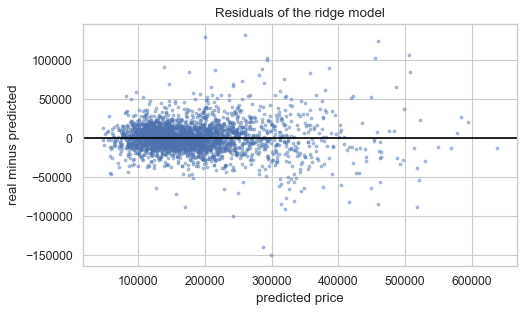

Mean absolute error for houses predicted below 150k: 9972  above 300k: 27419


In [16]:
residual = y - ridge_pred
plt.figure(figsize=(7, 4))
plt.scatter(ridge_pred, residual, s=6, alpha=0.4)
plt.axhline(0, color="black")
plt.xlabel("predicted price")
plt.ylabel("real minus predicted")
plt.title("Residuals of the ridge model")
plt.show()
print("Mean absolute error for houses predicted below 150k:", round(np.abs(residual[ridge_pred < 150000]).mean()),
      " above 300k:", round(np.abs(residual[ridge_pred > 300000]).mean()))

**What we see.** The residuals form a funnel: for houses predicted below 150,000 dollars the model misses by about **9,972** dollars on average, above 300,000 by **27,419**. In dollars, the error grows with the price; in percentages it is much more stable, which is the log-scale behaviour of Section 2 once more. A good report says "within about 8%" rather than one dollar figure for every house.

## ⚠️ Common pitfalls

- **Filling "none" as if it were "unknown".** A missing pool quality means *no pool*. Filling it with the most common quality would invent 2,917 pools.
- **Trusting the correlation ranking alone.** It misses categories such as neighbourhood, curved effects and outliers.
- **Deleting outliers without a reason.** Remove them only when you can say why they do not belong to the question, and report it.
- **Keeping near-duplicate columns in a linear model.** Coefficients become unstable and hard to interpret.
- **Reporting only R² or accuracy-like scores.** For prices, an error in dollars or percent is what the user of the model needs.
- **Forgetting to undo the log.** A model trained on `log(price)` predicts logs; convert back with `exp` before measuring the error.

## ✏️ Exercises

### Exercise 1 (The age of a house)
Create a column `Age` = `Yr Sold` minus `Year Built`. Plot the median price against age in groups of 10 years. Is the relationship straight?

In [17]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
df["Age"] = df["Yr Sold"] - df["Year Built"]
by_age = df.groupby(pd.cut(df["Age"], bins=range(0, 140, 10)))["SalePrice"].median()
print(by_age.round(0))
by_age.plot(marker="o", title="Median price by age of the house")
plt.show()
```

*Prices fall steeply over the first decades and then flatten out; the very oldest houses even recover a little, because the old houses that survive are often the well-built ones. A straight line would miss this shape.*
</details>

### Exercise 2 (Price per square foot)
Which neighbourhood has the highest median **price per square foot** of living area? Is it the same as the neighbourhood with the highest median price?

In [18]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
df["PricePerSqft"] = df["SalePrice"] / df["Gr Liv Area"]
per_sqft = df.groupby("Neighborhood")["PricePerSqft"].median().sort_values(ascending=False)
print(per_sqft.head(5).round(1))
```

*Price per square foot removes the effect of size, so it ranks neighbourhoods by how expensive the location itself is, and the order changes: some expensive neighbourhoods are expensive mainly because their houses are big. But check `df["Neighborhood"].value_counts()` before believing the top of the list: GrnHill and Greens have only a handful of sales, and a median of two or eight houses is fragile.*
</details>

### Exercise 3 (Does the log help a forest?)
Train the random forest of Section 7 on **log price** instead of price. Does its error change as much as the linear model's did? Why might that be?

In [19]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
forest_log = np.exp(cross_val_predict(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), Xn, np.log(y), cv=cv))
print("forest, log price:", round(mean_absolute_error(y, forest_log)))
```

*The forest changes very little. A tree splits on thresholds ("is the quality above 7?"), and a log does not change the order of the prices, so the splits stay much the same. Transformations matter most for models that assume straight lines.*
</details>

## 🔑 Key takeaways

- With many columns, **summarise before you read**: types, a missing-value count, a correlation ranking.
- **Read the documentation** before filling gaps: a missing value can mean *none*.
- A **skewed target** that grows in percentages is usually best modelled on a **log scale**.
- **Outliers** are removed only with a stated reason, and the removal is reported.
- **Categories** such as location need their own look; correlation tables only see numbers.
- Measure regression errors in **the units of the question** (dollars), and compare every model with the median baseline.
- Careful exploration can make a **simple model** as good as a complex one, and much easier to explain.

---
**Next:** *Notebook 04: Adult Census Income*, where the question is who earns more than 50,000 dollars a year, the classes are unbalanced, and we must ask whether a model is fair.

---
*© Ioannis Tsioulis. *From Questions to Answers: Classic Datasets, Fully Explored*. Prepared for educational use.*